# BrushCue Example: Color Reducer

<a href="https://colab.research.google.com/github/ditotechnologies/brushcue/blob/main/examples/color_reducer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

You can use this tool online at https://www.brushcue.com/tools/color-reducer

In [ ]:
!pip install brushcue

[wgpu] using backend Vulkan — adapter 'NVIDIA GeForce RTX 5070' (DiscreteGpu), driver 'NVIDIA'


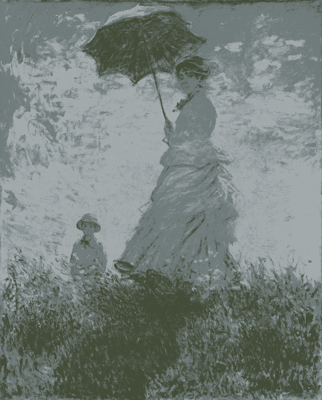

In [1]:
import io
from PIL import Image

import brushcue as bc

color_count = 3
input_image = bc.Composition.monet_women_with_parasol()
input_bounds = input_image.bounds()
uniform_scale = (100.0 / input_bounds.width()).min((100.0 / input_bounds.height()))
graph = input_image.palette_reduction(
    input_image.transform(
        bc.Transform2.identity().scale(
            bc.Vector2f.from_components(uniform_scale, uniform_scale)
        )
    ).to_palette(color_count)
)

ctx = bc.Context()
composition = graph.execute(ctx)
data_bytes = composition.to_image_bytes(ctx)
img = Image.open(io.BytesIO(data_bytes))
img.thumbnail((400, 400))  # Remove this line for full resolution
img
